<a href="https://colab.research.google.com/github/krishna25045678/Cleaning_home/blob/main/ProblemSet3_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning and Neural Networks

## Tutorial 3: Unsupervised learning

Welcome to the third tutorial for Machine Learning and Neural Netowkrs. In this session, we will explore how to apply some simple unsupervised learning algorithms. The first part of the tutorial explores Clustering, and the second Association Rules.

### Clustering

Throughout this section we will use routines implemented in scikit-learn.

#### Problem 1: K-Means clustering

Scikit-learn includes a number of datasets that you can use to test your models on. For this problem, we will use the [UCI Wine recognition](https://scikit-learn.org/1.5/datasets/toy_dataset.html#wine-recognition-dataset) dataset. Using that dataset, perform K-means clustering on the data and see if the clusters correspond to the production by each of the 3 producers (vinters).

This problem consists of a number of steps:
1. Load the dataset
2. Apply K-means to the data
  - First ask yourself: what is a reasonable number of clusters to try? 3!
3. Visualise the results
  - Plot the pairs of features coloured by clusters
  - And plot the true labels to compare with the clusters
4. Evaluate the model by calculating the interia, and by plotting the confusion matrix between the clusters and the true labels

##### Follow-up questions:

How well does K-means perform in separating the different Vinters?

What are the limitations of using K-means for this dataset?

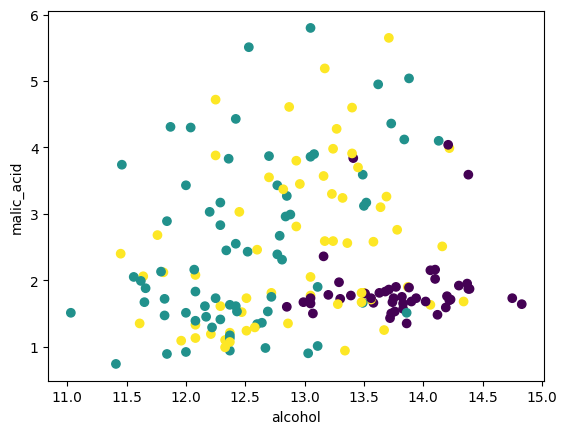

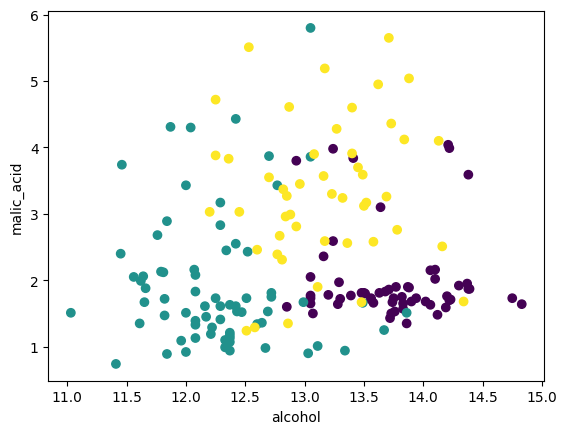

Inertia: 2370689.6867829696


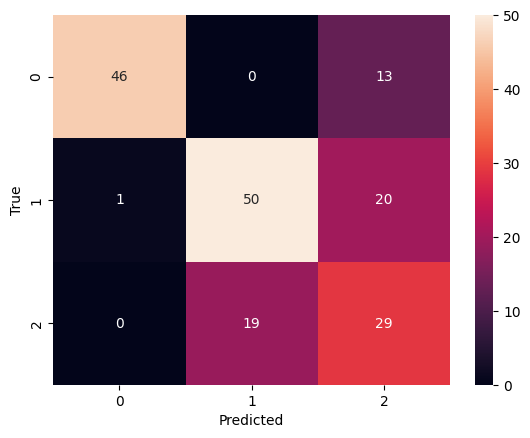

In [ ]:
# Put your solution here:

import sklearn

# load and examine the data
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)

X = wine.data
y = wine.target

X.head()

# set up the clustering
from sklearn.cluster import KMeans

# fit the clustering
k_means = KMeans(n_clusters=3)
k_means.fit(X)

# get the labels
labels = k_means.labels_

# plot the clusters
import matplotlib.pyplot as plt

plt.scatter(X['alcohol'], X['malic_acid'], c=labels)
plt.xlabel('alcohol')
plt.ylabel('malic_acid')
plt.show()

# plot the true labels
plt.scatter(X['alcohol'], X['malic_acid'], c=y)
plt.xlabel('alcohol')
plt.ylabel('malic_acid')
plt.show()

# print the inertia
print(f"Inertia: {k_means.inertia_}")

# evaluate the model
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y, labels)

# plot the confusion matrix:

import seaborn as sns

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

#### Problem 2: Finding the optimal number of clusters

The previous question used a fixed number of clusters. Now you should try to find the optimal number of clusters using the elbow method.

1. Elbow Method:
  - Implement a loop that fits K-means for a range of cluster numbers (K = 1 to 10).
  - For each value of K, compute and store the inertia (sum of squared distances from points to their assigned cluster center).
2. Plot the Elbow Curve:
  - Plot the inertia as a function of K.


Follow-up questions:

Based on the Elbow plot, what is the optimal number of clusters?

Does the optimal K match the known number of species in the Iris dataset? Why or why not?

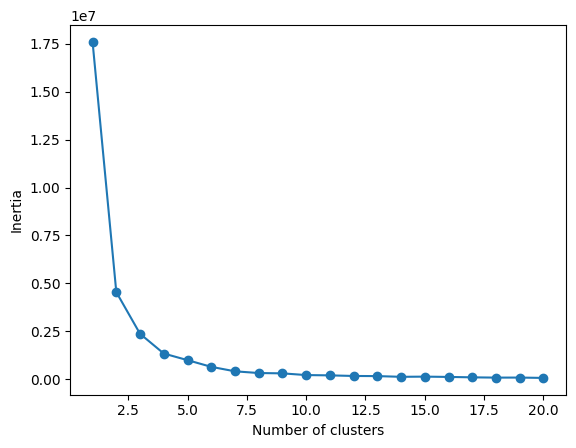

In [ ]:
# enter your solution here

# the previous answer is still available, so I will just add the looping and plotting:

inertias = []

max_clusters = 20

for k in range(1, max_clusters+1):
    k_means = KMeans(n_clusters=k)
    k_means.fit(X)
    inertias.append(k_means.inertia_)


plt.plot(range(1, max_clusters+1), inertias, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.show()

#### Problem 3: Clustering high-dimensional data

For this problem, we will use the [UCI Hand-written digits](https://scikit-learn.org/1.5/datasets/toy_dataset.html#optical-recognition-of-handwritten-digits-dataset) dataset. This dataset now has 8x8 pixels in each sample, so the dimensionality is much higher and you might not be able to easily visualise whether it is working. Using that dataset, perform K-means clustering on the data and see if the clusters correspond to the digits.

This problem consists of a number of steps:
1. Load the dataset
2. Apply K-means to the data
  - First ask yourself: what is a reasonable number of clusters to try? 10!
3. Evaluate the results
  - Plot the confusion matrix and inertia of the results
4. Apply one of [Dimensionality reduction](https://scikit-learn.org/1.5/modules/unsupervised_reduction.html) approaches in scikit-learn to the data and then try to cluster it again. Produce the same outputs and see if they improve as you change the amount you reduce the dimensionality of the data

Text(95.72222222222221, 0.5, 'True')

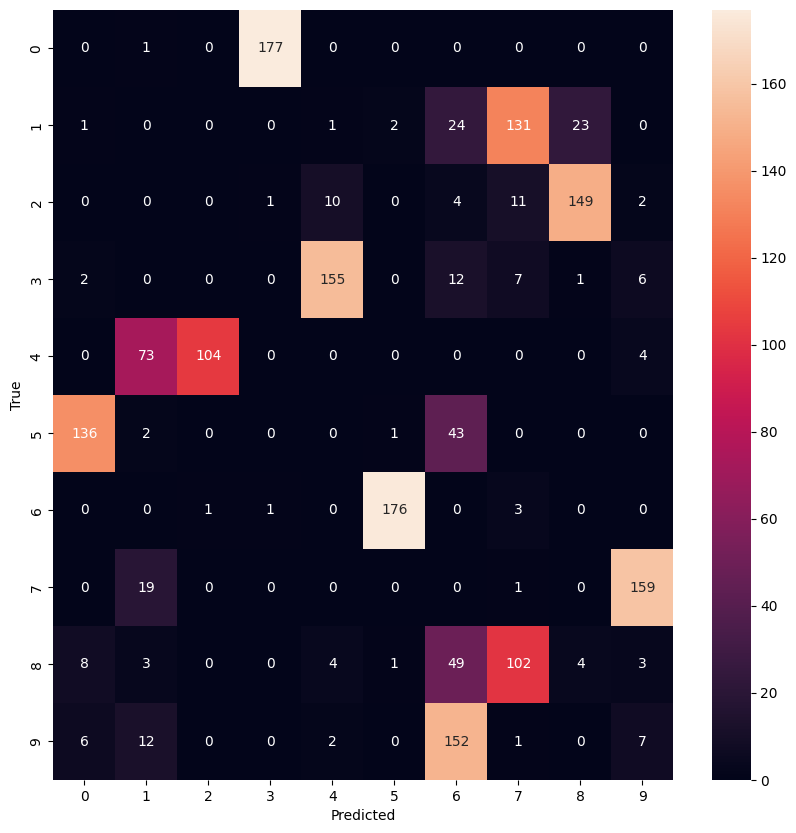

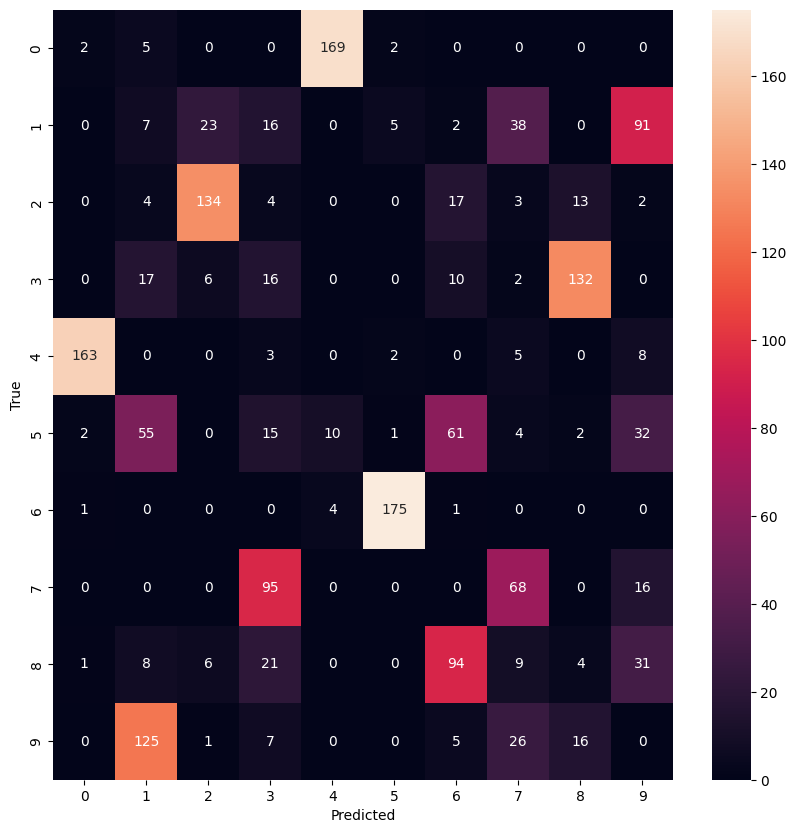

In [ ]:
# emter your solution here:

# load the data
from sklearn.datasets import load_digits

digits = load_digits(as_frame=True)

X = digits.data
y = digits.target

# train the model
k_means = KMeans(n_clusters=10)
k_means.fit(X)

# evaluate the model
labels = k_means.labels_

cm = confusion_matrix(y, labels)

# plot the confusion matrix:

import seaborn as sns
fig = plt.figure(figsize=(10,10))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')
plt

# Now try PCA first:

from sklearn.decomposition import PCA

pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)

k_means = KMeans(n_clusters=10)
k_means.fit(X_pca)

labels = k_means.labels_

cm = confusion_matrix(y, labels)

# plot the confusion matrix:

fig2 = plt.figure(figsize=(10,10))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')

#### Problem 4: Gaussian Mixture Models

Now we will come back to the wine dataset. Reload that data and apply a Gaussian Mixture Model instead of k-means. Use the optimal number of clusters that you found above for the number of mixtures.

1. Apply GMM:
  - Use GaussianMixture from scikit-learn to apply GMM to the Wine dataset.
2. Cluster Visualization:
  - Visualize the clusters formed by GMM using the same two features as in Question 1.
  - Compare the clustering result with the true class labels and with the K-means result.
3. Probability Assignment:
  - Instead of hard assignments (as in K-means), GMM provides the probability that each point belongs to a cluster. Extract these probabilities for one of the clusters and plot them for all points.


Follow-up questions:

How do the GMM clusters compare to the K-means clusters?

Which model seems to perform better for this dataset?

What is the significance of the soft assignment in GMM, and in what cases is GMM preferred over K-means?

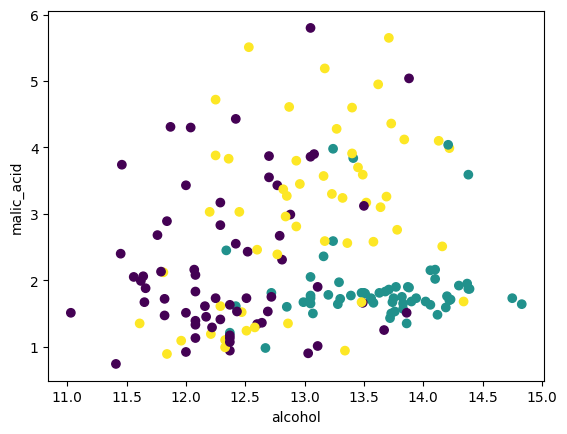

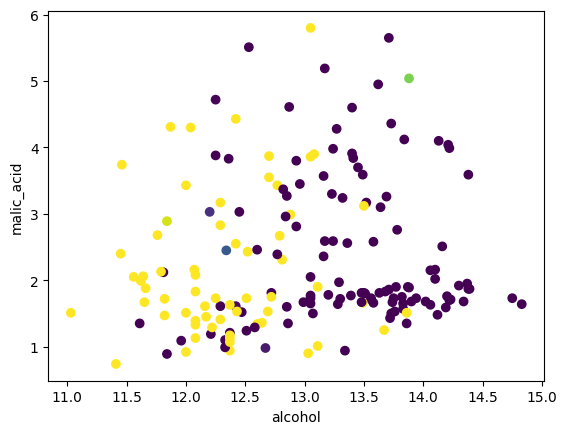

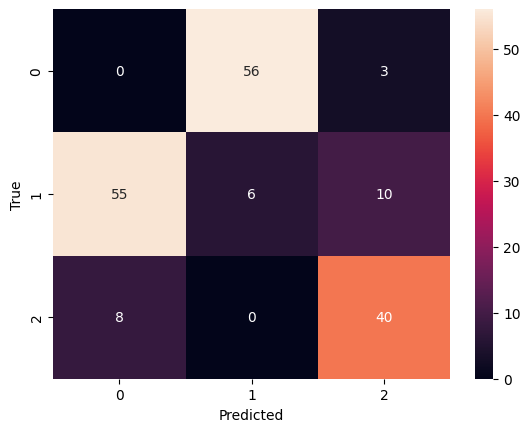

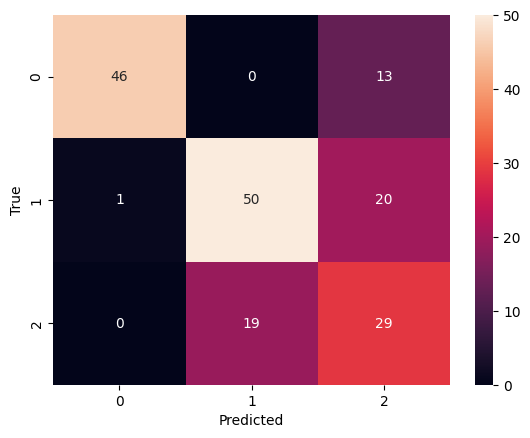

In [ ]:
# enter your solution here:

# load the data


wine = load_wine(as_frame=True)

X = wine.data
y = wine.target

X.head()

# import the GMM
from sklearn.mixture import GaussianMixture

# train the model
gmm = GaussianMixture(n_components=3)
gmm.fit(X)

# evaluate the model
labels = gmm.predict(X)

# plot the clusters
plt.scatter(X['alcohol'], X['malic_acid'], c=labels)
plt.xlabel('alcohol')
plt.ylabel('malic_acid')
plt.show()

# plot the probabilities for the first cluster:

plt.scatter(X['alcohol'], X['malic_acid'], c=gmm.predict_proba(X)[:,0])
plt.xlabel('alcohol')
plt.ylabel('malic_acid')
plt.show()

# compare with the true classes as a confusion matrix

cm = confusion_matrix(y, labels)

# plot the confusion matrix:

import seaborn as sns

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# compare these results to those from K-means

cm = confusion_matrix(y, k_means.labels_)

# plot the confusion matrix:

import seaborn as sns

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


### Association Rules

#### Problem 5: Association Rule Mining

Now we will switch tack, both in topic and in the package we are using. You will construct association rules on the [Market Basket Optimisation](https://www.kaggle.com/datasets/devchauhan1/market-basket-optimisationcsv) dataset from kaggle. Since scikit-learn doesn't provide many association rule methods, you will use the mlxtend package for this.

1. Load the dataset
2. Use the apriori function from the mlxtend.frequent_patterns module to generate frequent itemsets with a minimum support of 0.15
3. Use the association_rules function to generate rules based on the frequent itemsets, using confidence as the metric with a threshold of 0.6.
4. Analysis:
  - Print the top 5 association rules sorted by lift.
  - Interpret the results: What do the top rules suggest about item co-occurrences?

Follow-up questions:

What does a high confidence score in an association rule mean?

How does the lift metric help in identifying more useful rules?

What are some potential applications of association rule mining in a retail setting?

In [ ]:
# enter your solution here:

# load the data
import pandas as pd

df = pd.read_csv('Market_Basket_Optimisation.csv', header=None)

# check the data
df.head()

# re-organise the data!
transactions = []
for i in range(0, 7501):
    transactions.append([str(df.values[i,j]) for j in range(0, 20)])

from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)
df

# import apriori from mlxtend
from mlxtend.frequent_patterns import apriori, association_rules

min_support = 0.15
min_confidence = 0.6

# generate the frequent itemsets
apriori(df, min_support=min_support)

# generate the rules
rules = association_rules(apriori(df, min_support=min_support),
                          metric="confidence", min_threshold=min_confidence)

# print the top 5 rules
rules.sort_values(by='lift', ascending=False).head()


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction,zhangs_metric
0,(25),(77),0.163845,0.999867,0.163845,1.000000,1.000133,0.000022,inf,0.000159
1,(37),(77),0.179709,0.999867,0.179709,1.000000,1.000133,0.000024,inf,0.000163
2,(43),(77),0.170911,0.999867,0.170911,1.000000,1.000133,0.000023,inf,0.000161
4,(101),(77),0.174110,0.999867,0.174110,1.000000,1.000133,0.000023,inf,0.000161
3,(72),(77),0.238368,0.999867,0.238235,0.999441,0.999574,-0.000102,0.238368,-0.000559
